# 3. Préparer les entrées, et explorer leur structure

**Prédiction de la qualité des soudures**

Marie Gozlan, Jules Mortreux, Grégoire Pascual, Pétronille Tard

---

## Ce que fait ce notebook

Le notebook 1 a établi ce que contiennent les données. Le notebook 2 a construit
la variable à prédire. Celui-ci traite les **entrées**, c'est-à-dire la
composition chimique et les paramètres du procédé, et explore leur structure
sans utiliser la cible.

Il se divise en deux parties que rien n'oblige à séparer, mais qui répondent à
des questions différentes.

**La préparation**, sections 1 à 3. Les modèles n'acceptent pas de valeurs
absentes ni de texte, et certains sont sensibles aux unités. Cinq décisions sont
nécessaires, et chacune a un coût qu'il faut connaître.

**L'exploration non supervisée**, sections 4 et 5. L'analyse en composantes
principales et le partitionnement par k-moyennes ne regardent jamais la cible.
Ils servent à comprendre la structure des entrées, et à répondre à une question
précise : **les soudures se regroupent-elles naturellement par niveau de
qualité ?** La réponse est non, et c'est un résultat utile.

## Un résultat que nous avons dû corriger

Nous avions d'abord conclu que l'imputation des valeurs manquantes était
responsable de la structure plate observée par l'analyse en composantes
principales. En voulant le démontrer proprement, **nous nous sommes aperçus que
notre première comparaison était biaisée** : elle opposait une analyse sur
vingt-deux colonnes à une analyse sur onze, donc l'écart mélangeait l'effet de
l'imputation et celui de la dimension.

La section 4 reprend la démonstration avec un protocole qui tient tout le reste
constant. La conclusion initiale se trouve confirmée, mais elle n'était pas
établie par le premier calcul, et nous préférons le dire.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import adjusted_rand_score, mean_squared_error
from sklearn.metrics import silhouette_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd()
while not (ROOT / "data" / "raw").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
OUT = ROOT / "outputs" / "rendu3"
OUT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "src"))
import export_processed as nettoyage

GRAINE = 42
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})

CATEGORIES = ["AC_DC", "Electrode_pol", "WeldType"]
donnees = pd.read_csv(ROOT / "outputs/rendu2/dataset_qualite.csv",
                      index_col="row_id",
                      dtype={c: str for c in CATEGORIES + ["WeldID", "partition"]},
                      keep_default_na=False, na_values=[""],
                      float_precision="round_trip")

VARIABLES = nettoyage.COMPOSITION + nettoyage.PROCESS
NUMERIQUES = [c for c in VARIABLES if c not in CATEGORIES]
dev = donnees["partition"] == "developpement"

X = donnees.loc[dev, VARIABLES]
y = donnees.loc[dev, "score_qualite"]
groupes = donnees.loc[dev, "groupe"]

print(f"Développement : {len(X)} lignes, {groupes.nunique()} soudures.")
print(f"{len(VARIABLES)} variables d'entrée, dont {len(CATEGORIES)} "
      f"catégorielles et {len(NUMERIQUES)} numériques.")

Développement : 527 lignes, 376 soudures.
30 variables d'entrée, dont 3 catégorielles et 27 numériques.


## 1. Cinq décisions de préparation

### 1.1 Écarter les colonnes trop vides

Certaines colonnes sont renseignées pour moins d'un dixième des soudures. Les
conserver signifierait inventer plus de neuf valeurs sur dix, pour une colonne
qui n'apporte presque rien.

**Nous retenons les colonnes renseignées à au moins 25 %.** Ce seuil n'est pas
une règle du cours, et il serait légitime de le contester. Nous ne le défendons
donc pas par principe, mais par un argument vérifiable : **aucune colonne ne se
trouve à proximité de ce seuil.** Les colonnes sont soit nettement au-dessus,
soit nettement en dessous, de sorte que déplacer le seuil de quelques points ne
changerait rien à la sélection.

La cellule suivante le vérifie, en mesurant la distance de chaque colonne au
seuil.

In [2]:
SEUIL_REMPLISSAGE = 0.25
remplissage = X.notna().mean().sort_values()
gardees = remplissage[remplissage >= SEUIL_REMPLISSAGE].index.tolist()
ecartees = remplissage[remplissage < SEUIL_REMPLISSAGE].index.tolist()

print(f"{len(gardees)} colonnes conservées, {len(ecartees)} écartées.")
print(f"Écartées : {ecartees}\n")

distance = (remplissage - SEUIL_REMPLISSAGE).abs().sort_values()
marges = pd.DataFrame({
    "remplissage": remplissage[distance.index[:6]],
    "distance au seuil": distance[:6],
})
print("Les six colonnes les plus proches du seuil :")
display(marges.round(3))
print(f"La plus proche est à {distance.iloc[0]:.1%} du seuil, soit "
      f"{distance.iloc[0] * len(X):.0f} lignes.")
print("Un déplacement du seuil de quelques points ne ferait donc basculer")
print("aucune colonne.")

25 colonnes conservées, 5 écartées.
Écartées : ['As_ppm', 'Sb_ppm', 'Sn_ppm', 'Co', 'W']

Les six colonnes les plus proches du seuil :


,remplissage,distance au seuil
B_ppm,0.370,0.120
Co,0.129,0.121
W,0.129,0.121
Sn_ppm,0.125,0.125
Sb_ppm,0.106,0.144
Cu,0.397,0.147


La plus proche est à 12.0% du seuil, soit 63 lignes.
Un déplacement du seuil de quelques points ne ferait donc basculer
aucune colonne.


### 1.2 Remplacer les valeurs numériques absentes par la médiane

**Pourquoi la médiane et non la moyenne.** Le notebook 1 a montré que les
concentrations sont très dispersées, avec des valeurs extrêmes. Une seule valeur
aberrante déplace la moyenne de façon sensible, alors qu'elle ne déplace
quasiment pas la médiane. C'est le même raisonnement que celui qui fait
préférer les bornes interquartiles à l'écart-type pour détecter les valeurs
aberrantes.

**Ce que cela coûte**, et le notebook 1 l'a chiffré : remplacer une proportion
`1 - p` des valeurs par une constante contracte l'écart-type d'un facteur
`racine(p)`. La section 4 montrera les conséquences de cette contraction.

**Une incohérence que nous avons trouvée dans notre propre chaîne de
traitement**, et qu'il faut signaler.

Tout le projet pondère par soudure, pour qu'une soudure testée vingt fois ne
pèse pas vingt fois. Mais la médiane calculée par `SimpleImputer` est **non
pondérée** : elle est tirée vers les soudures sur-représentées. Nous mesurons
l'ampleur du problème plutôt que de le supposer négligeable.

In [3]:
def mediane_ponderee(valeurs, poids):
    """Médiane où chaque observation compte selon son poids."""
    table = pd.DataFrame({"valeur": valeurs, "poids": poids}).dropna()
    table = table.sort_values("valeur")
    cumul = table["poids"].cumsum() / table["poids"].sum()
    return float(table["valeur"].iloc[np.searchsorted(cumul.to_numpy(), 0.5)])


poids = 1 / groupes.map(groupes.value_counts())
numeriques_gardees = [c for c in gardees if c not in CATEGORIES]

lignes_medianes = []
for colonne in numeriques_gardees:
    ordinaire = X[colonne].median()
    ponderee = mediane_ponderee(X[colonne], poids)
    lignes_medianes.append({
        "colonne": colonne,
        "remplissage": X[colonne].notna().mean(),
        "médiane ordinaire": ordinaire,
        "médiane pondérée": ponderee,
        "écart relatif": abs(ponderee - ordinaire) / abs(ordinaire)
                         if ordinaire != 0 else np.nan,
    })
effet_ponderation = pd.DataFrame(lignes_medianes).set_index("colonne")

identiques = (effet_ponderation["écart relatif"] < 1e-9).sum()
print(f"Sur {len(effet_ponderation)} colonnes, {identiques} ont exactement la "
      "même médiane pondérée ou non.")
print(f"Écart relatif médian : "
      f"{effet_ponderation['écart relatif'].median():.1%}")
print(f"Écart relatif maximal : "
      f"{effet_ponderation['écart relatif'].max():.1%}\n")
print("Les cinq plus grands écarts :")
display(effet_ponderation.sort_values("écart relatif", ascending=False)
        .head(5).round(4))

Sur 22 colonnes, 12 ont exactement la même médiane pondérée ou non.
Écart relatif médian : 0.0%
Écart relatif maximal : 57.4%

Les cinq plus grands écarts :


,remplissage,médiane ordinaire,médiane pondérée,écart relatif
colonne,,,,
Ni,0.4478,0.0235,0.010,0.5745
Mo,0.4573,0.0100,0.015,0.5000
Al_ppm,0.5977,20.0000,25.000,0.2500
PWHT_time_h,1.0000,2.0000,2.100,0.0500
Cu,0.3966,0.0410,0.043,0.0488


### Ce que l'incohérence coûte réellement

**Pour une majorité de colonnes, la médiane pondérée est exactement la même.**
C'est logique : la médiane est une valeur observée, et il faut un déplacement
important de la masse pour qu'elle change de valeur.

**Les écarts notables se concentrent sur les colonnes les moins renseignées.**
Les trois plus touchées sont des éléments d'alliage rarement mesurés, pour
lesquels la médiane est calculée sur peu de valeurs et réagit donc beaucoup à la
pondération.

**Conclusion, et nous l'assumons telle quelle.** L'incohérence est réelle mais
son effet se concentre sur les colonnes les plus pauvres, qui sont aussi celles
dont la médiane remplace le plus de valeurs, donc celles qui portent le moins
d'information exploitable. Nous conservons `SimpleImputer` pour la lisibilité du
code et parce qu'il s'intègre naturellement dans un pipeline, en ayant mesuré ce
que ce choix coûte.

**Ce qu'il faudrait faire si l'on voulait être rigoureux jusqu'au bout** est de
calculer les médianes pondérées à la main et de les passer à un imputeur
constant, réajusté dans chaque pli. C'est une quinzaine de lignes de code, et
nous l'inscrivons dans les améliorations possibles plutôt que de le passer sous
silence.

### 1.3 Créer une catégorie pour les valeurs catégorielles absentes

Pour les variables de texte, nous n'imputons pas par la valeur la plus
fréquente : **nous créons une catégorie `manquant`**.

La justification vient directement du notebook 1. Les absences suivent le
protocole expérimental, donc nous sommes dans un mécanisme **aléatoire
conditionnellement** et non complètement aléatoire. **L'absence est elle-même une
information** : elle renseigne indirectement sur le type d'étude, donc sur le
type de soudure.

Imputer par la valeur la plus fréquente détruirait cette information en
affirmant qu'un procédé non renseigné était forcément le plus courant. Créer une
catégorie la conserve, et laisse le modèle décider si elle est utile.

### 1.4 Encoder les catégories, en retirant une modalité

Un modèle numérique ne peut pas traiter la chaîne `MMA`. L'encodage dit
**one-hot** remplace une variable à `k` modalités par `k` colonnes valant 0 ou 1.

**Nous retirons une modalité par variable, et ce n'est pas une coquetterie.**
Avec les `k` colonnes et une constante dans le modèle, leur somme vaut exactement
1 sur toutes les lignes : les colonnes sont linéairement dépendantes. La matrice
du système des moindres carrés n'est alors plus inversible, et la solution n'est
plus unique. C'est ce qu'on appelle le piège des variables muettes.

Retirer une modalité lève la dépendance. La modalité retirée devient la
**référence**, et les coefficients des autres se lisent par rapport à elle.

Pour les arbres de décision, cela n'a aucune importance, puisqu'ils ne résolvent
aucun système linéaire. Nous conservons néanmoins le même encodage pour tous les
modèles, afin qu'ils reçoivent exactement les mêmes entrées.

**Une limite à connaître.** Nous demandons à l'encodeur d'ignorer les modalités
inconnues plutôt que d'échouer. Une modalité jamais vue en apprentissage reçoit
donc des indicateurs tous nuls, ce qui la rend **indistinguable de la modalité de
référence**. C'est silencieux, et il faut le savoir.

### 1.5 Standardiser, mais seulement pour certains modèles

Standardiser consiste à centrer chaque colonne sur zéro et à la ramener à un
écart-type de un. Deux familles de modèles en ont besoin, pour deux raisons
différentes qu'il vaut mieux distinguer.

**Les modèles qui raisonnent en distances**, comme les k plus proches voisins ou
les machines à vecteurs de support. Sans standardisation, une variable exprimée
en centaines de parties par million écraserait mécaniquement une variable
exprimée en pourcents, non parce qu'elle est plus informative mais parce que ses
nombres sont plus grands.

**Les modèles à pénalité**, comme les régressions ridge et lasso, et c'est
l'argument le plus fort. Leur pénalité porte sur la **taille des coefficients**.
Si deux variables ont des unités d'échelles très différentes, leurs coefficients
aussi, donc la pénalité les frappe inégalement. Sans standardisation, ces
modèles pénalisent arbitrairement selon les unités choisies.

**Les arbres et les méthodes d'ensemble n'en ont pas besoin**, parce qu'ils ne
comparent que des seuils **à l'intérieur d'une même variable**. Multiplier une
colonne par mille ne change aucune de leurs décisions.

La standardisation est donc une option de notre fonction de préparation, activée
par les modèles qui la requièrent.

In [4]:
def creer_preparation(X_apprentissage, normaliser=False, indicateurs=False,
                      n_axes=None, seuil=SEUIL_REMPLISSAGE):
    """Assemble les cinq décisions de préparation en un transformateur.

    Toutes les statistiques, sélection de colonnes, médianes, modalités vues et
    paramètres de standardisation, sont apprises sur le seul echantillon
    d'apprentissage passé en argument. C'est ce qui rend la préparation
    réajustable dans chaque pli de validation, comme l'exige la section 2.
    """
    taux = X_apprentissage.notna().mean()
    retenues = taux[taux >= seuil].index.tolist()
    numeriques = [c for c in retenues if c not in CATEGORIES]
    categorielles = [c for c in retenues if c in CATEGORIES]

    etapes = [("mediane", SimpleImputer(strategy="median",
                                        add_indicator=indicateurs))]
    if normaliser:
        etapes.append(("standardisation", StandardScaler()))
    if n_axes is not None:
        etapes.append(("acp", PCA(n_components=min(n_axes, len(numeriques)),
                                  random_state=GRAINE)))

    return ColumnTransformer([
        ("nombres", Pipeline(etapes), numeriques),
        ("categories", Pipeline([
            ("manquants", SimpleImputer(strategy="constant",
                                        fill_value="manquant")),
            ("encodage", OneHotEncoder(drop="first", handle_unknown="ignore",
                                       sparse_output=False)),
        ]), categorielles),
    ])


preparation = creer_preparation(X, normaliser=True)
X_prepare = pd.DataFrame(preparation.fit_transform(X), index=X.index,
                         columns=[n.split("__")[-1]
                                  for n in preparation.get_feature_names_out()])

print(f"Avant : {X.shape[1]} colonnes, dont {len(CATEGORIES)} de texte, "
      f"avec des valeurs absentes.")
print(f"Après : {X_prepare.shape[1]} colonnes, toutes numériques, "
      "sans valeur absente.")
assert np.isfinite(X_prepare.to_numpy()).all()
print(f"\nLes {len(CATEGORIES)} variables de texte ont produit "
      f"{X_prepare.shape[1] - len(numeriques_gardees)} indicateurs.")
display(X_prepare.iloc[:3, :8].round(3))

Avant : 30 colonnes, dont 3 de texte, avec des valeurs absentes.
Après : 34 colonnes, toutes numériques, sans valeur absente.

Les 3 variables de texte ont produit 12 indicateurs.


,C,Si,Mn,S,P,Ni,Cr,Mo
row_id,,,,,,,,
0,-1.695,-0.310,-1.368,-0.222,-0.06,-0.328,-0.332,-0.418
2,-1.695,-0.310,-1.368,-0.222,-0.06,-0.328,-0.332,-0.418
3,-1.695,-0.238,-0.401,-0.353,0.10,-0.328,-0.332,-0.418


## 2. La règle qui compte : réajuster dans chaque pli

C'est la section la plus importante du notebook, et la plus facile à survoler.

### Le problème

Nous allons comparer des modèles par validation croisée : découper le
développement en cinq paquets, entraîner sur quatre, évaluer sur le cinquième.

**Si la préparation est faite une fois pour toutes avant ce découpage, quatre
choses fuient** des lignes de validation vers l'apprentissage :

- les **médianes d'imputation**, calculées sur toutes les lignes ;
- les **paramètres de standardisation**, moyenne et écart-type de chaque colonne ;
- la **liste des modalités** vues par l'encodeur ;
- et la **sélection des colonnes** elle-même, puisque le taux de remplissage est
  calculé sur toutes les lignes.

Dans les quatre cas, nous aurions utilisé les lignes de validation pour
fabriquer la transformation. La performance mesurée serait alors optimiste, et
d'autant plus que les transformations sont ajustées sur peu de données.

### La solution, et pourquoi elle passe par un pipeline

**Toute la préparation est placée dans un `Pipeline`**, et c'est la seule raison
qui compte. Ce n'est pas une question de propreté du code : la validation croisée
de scikit-learn **réajuste l'intégralité du pipeline à chaque pli**. Mettre la
préparation dedans rend la fuite impossible par construction ; la laisser dehors
la rend garantie.

La cellule suivante vérifie la règle, sans entraîner aucun modèle. Elle contrôle
aussi que les groupes sont disjoints, et elle mesure de combien les médianes
varient d'un pli à l'autre, ce qui donne une idée de ce qui aurait fui.

In [5]:
verification, medianes_par_pli = [], []

for numero, (train, validation) in enumerate(
        GroupKFold(n_splits=5).split(X, groups=groupes), start=1):
    X_train, X_validation = X.iloc[train], X.iloc[validation]
    assert set(groupes.iloc[train]).isdisjoint(set(groupes.iloc[validation])), \
        "une soudure est à cheval sur l'apprentissage et la validation"

    # Préparation ajustée sur l'apprentissage du pli SEULEMENT, puis appliquée
    # à la validation sans nouvel ajustement.
    preparation_pli = creer_preparation(X_train, normaliser=True)
    train_prepare = preparation_pli.fit_transform(X_train)
    validation_preparee = preparation_pli.transform(X_validation)

    assert np.isfinite(train_prepare).all()
    assert np.isfinite(validation_preparee).all()
    assert train_prepare.shape[1] == validation_preparee.shape[1]

    taux_pli = X_train.notna().mean()
    retenues_pli = taux_pli[taux_pli >= SEUIL_REMPLISSAGE].index.tolist()
    verification.append({
        "pli": numero,
        "lignes d'apprentissage": len(train),
        "lignes de validation": len(validation),
        "colonnes retenues": len(retenues_pli),
        "colonnes après encodage": train_prepare.shape[1],
        "sélection identique": sorted(retenues_pli) == sorted(gardees),
    })
    medianes_par_pli.append(X_train[numeriques_gardees].median())

display(pd.DataFrame(verification).set_index("pli"))

ecart_medianes = pd.DataFrame(medianes_par_pli).agg(["min", "max"]).T
ecart_medianes["amplitude relative"] = (
    (ecart_medianes["max"] - ecart_medianes["min"])
    / ecart_medianes["max"].abs().replace(0, np.nan))
print("Variation des médianes d'imputation entre les cinq plis :")
display(ecart_medianes.sort_values("amplitude relative", ascending=False)
        .head(5).round(4))
print("Ces écarts sont exactement ce qui aurait fui si la préparation")
print("avait été ajustée une seule fois, avant le découpage.")

C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,lignes d'apprentissage,lignes de validation,colonnes retenues,colonnes après encodage,sélection identique
pli,,,,,
1,421,106,25,34,True
2,421,106,25,33,True
3,422,105,25,34,True
4,422,105,25,34,True
5,422,105,25,33,True


Variation des médianes d'imputation entre les cinq plis :


,min,max,amplitude relative
Ni,0.0000,0.0300,1.000
Al_ppm,2.5000,25.0000,0.900
Mo,0.0100,0.0160,0.375
Cr,0.0370,0.0500,0.260
V,0.0003,0.0004,0.250


Ces écarts sont exactement ce qui aurait fui si la préparation
avait été ajustée une seule fois, avant le découpage.


### Ce que la vérification établit

**La sélection des colonnes est identique dans les cinq plis**, ce qui confirme
l'argument de la section 1.1 : le seuil est loin de toute colonne, donc il ne
bascule pas.

**Le nombre de colonnes après encodage peut varier d'un pli à l'autre**, et c'est
normal : si une modalité rare de procédé est absente de l'apprentissage d'un pli,
l'encodeur ne crée pas son indicateur. Notre fonction d'évaluation accepte cette
variation, puisque chaque pli entraîne son propre modèle.

**Les médianes, en revanche, varient**, et parfois de plusieurs dizaines de
pourcents sur les colonnes les moins renseignées. C'est une mesure directe de
l'information qui aurait fui : une médiane calculée sur tout le développement
contient une part des lignes de validation.

## 3. Les indicateurs de valeurs manquantes

La section 1.3 a établi que l'absence d'une valeur porte de l'information,
puisqu'elle dépend du protocole expérimental. Pour les variables catégorielles,
nous la conservons par une catégorie dédiée. **Pour les variables numériques,
rien de tel : une fois la médiane substituée, le modèle ne peut plus distinguer
une valeur mesurée d'une valeur inventée.**

Scikit-learn propose de remédier à cela en ajoutant, pour chaque colonne
concernée, une colonne valant 1 si la valeur d'origine était absente et 0 sinon.
C'est l'option `add_indicator`, prévue dans notre fonction de préparation.

**Est-ce utile ?** La question se tranche par l'expérience, et elle a une réponse
nuancée que nous avons mesurée dans le notebook d'exploration
`notebooks/12_reentrainement_cible_y3.ipynb` : **les deux modèles à pénalité
retiennent la version avec indicateurs, la régression linéaire sans pénalité
retient la version sans.**

L'explication est le compromis biais-variance. Ces colonnes portent une
information réelle, donc elles réduisent le biais. Mais elles sont nombreuses, et
sur un échantillon de cinq cents lignes, chacune est une occasion
supplémentaire de surapprendre. **La pénalité paie ce coût ; un modèle sans
pénalité ne le paie pas.**

La cellule suivante mesure simplement combien de colonnes l'option ajoute, pour
que l'ordre de grandeur soit clair.

In [6]:
sans = creer_preparation(X, normaliser=True)
avec = creer_preparation(X, normaliser=True, indicateurs=True)
colonnes_sans = sans.fit_transform(X).shape[1]
colonnes_avec = avec.fit_transform(X).shape[1]

incompletes = [c for c in numeriques_gardees if X[c].isna().any()]
print(f"Colonnes numériques retenues comportant au moins une absence : "
      f"{len(incompletes)}")
print(f"Colonnes après préparation, sans indicateurs : {colonnes_sans}")
print(f"Colonnes après préparation, avec indicateurs : {colonnes_avec}")
print(f"\nL'option ajoute {colonnes_avec - colonnes_sans} colonnes, soit "
      f"{(colonnes_avec - colonnes_sans) / colonnes_sans:+.0%}.")
print(f"Pour {len(X)} lignes d'apprentissage, c'est un coût réel en variance.")

Colonnes numériques retenues comportant au moins une absence : 15
Colonnes après préparation, sans indicateurs : 34
Colonnes après préparation, avec indicateurs : 49

L'option ajoute 15 colonnes, soit +44%.
Pour 527 lignes d'apprentissage, c'est un coût réel en variance.


## 4. L'analyse en composantes principales, et ce que l'imputation lui fait

### 4.1 Ce que fait la méthode, en bref

Nos entrées comptent plusieurs dizaines de colonnes, souvent corrélées entre
elles : les aciers riches en un élément le sont souvent en d'autres, par les
nuances employées. L'analyse en composantes principales cherche de **nouvelles
directions**, combinaisons des colonnes d'origine, telles que la première capte
le maximum de variance, la deuxième le maximum de ce qui reste en étant
perpendiculaire à la première, et ainsi de suite.

L'intérêt est double : représenter les données en deux dimensions pour les
regarder, et savoir **combien de directions sont nécessaires** pour résumer
l'information. Si deux axes suffisaient, la structure serait simple ; s'il en
faut beaucoup, elle est intrinsèquement multidimensionnelle.

Elle ne regarde jamais la cible : c'est une méthode **non supervisée**. Elle ne
peut donc pas dire quelles variables font une bonne soudure, seulement lesquelles
varient ensemble.

### 4.2 Le résultat sur nos données préparées

In [7]:
numeriques_prepares = [c for c in X_prepare.columns
                       if c in numeriques_gardees]
Z = X_prepare[numeriques_prepares].to_numpy()
acp = PCA(random_state=GRAINE).fit(Z)
variance = acp.explained_variance_ratio_
cumul = np.cumsum(variance)

resume_acp = pd.DataFrame({
    "axe": np.arange(1, len(variance) + 1),
    "variance expliquée": variance,
    "variance cumulée": cumul,
}).set_index("axe")

print(f"{Z.shape[1]} variables numériques, {Z.shape[0]} lignes.")
print(f"Premier axe : {variance[0]:.1%} de la variance.")
print(f"Deux premiers axes : {variance[:2].sum():.1%}.")
print(f"Axes nécessaires pour atteindre 80 % : "
      f"{int(np.argmax(cumul >= 0.80) + 1)}")
print(f"Axes nécessaires pour atteindre 90 % : "
      f"{int(np.argmax(cumul >= 0.90) + 1)}")
display(resume_acp.head(6).round(4))

22 variables numériques, 527 lignes.
Premier axe : 18.1% de la variance.
Deux premiers axes : 34.3%.
Axes nécessaires pour atteindre 80 % : 11
Axes nécessaires pour atteindre 90 % : 14


,variance expliquée,variance cumulée
axe,,
1,0.1815,0.1815
2,0.1617,0.3431
3,0.0866,0.4297
4,0.0682,0.4979
5,0.0588,0.5567
6,0.0543,0.6110


**La structure est plate.** Les deux premiers axes n'expliquent qu'environ un
tiers de la variance, et il faut une dizaine d'axes pour atteindre 80 %. Un
graphique en deux dimensions ne montre donc qu'une petite part de l'information.

Pour comparaison, le jeu de données du TD 1 sur la criminalité aux États-Unis
atteignait près de 87 % sur deux axes. Nos données sont d'une nature très
différente : trente variables physiques faiblement redondantes, là où ce jeu
comportait quatre indicateurs mesurant largement la même chose.

**Mais une part de cette platitude pourrait être un artefact de notre
imputation**, et c'est ce que la section suivante établit.

### 4.3 L'imputation aplatit-elle l'analyse ? Le protocole

Le raisonnement à vérifier est le suivant. L'analyse repose entièrement sur les
variances et les corrélations. Le notebook 1 a montré que l'imputation par une
constante les **contracte** d'un facteur `racine(p)`. Des variances contractées
devraient donc produire des axes expliquant moins de variance.

**Notre première tentative de démonstration était biaisée, et nous la
rapportons pour que l'erreur serve.** Nous avions comparé l'analyse ci-dessus,
sur vingt-deux colonnes imputées, à une analyse sur les seules colonnes bien
renseignées, sans imputation. L'écart était spectaculaire, mais **les deux
analyses n'avaient pas le même nombre de colonnes**. Or réduire le nombre de
colonnes concentre mécaniquement la variance sur moins d'axes, indépendamment de
toute imputation. L'écart mélangeait donc deux effets.

**Le protocole correct tient tout constant sauf l'imputation.** Nous partons des
colonnes bien renseignées, restreintes aux lignes où elles sont **toutes**
présentes : une base sans aucune valeur absente. Puis nous **masquons
artificiellement** une proportion croissante de valeurs, nous imputons par la
médiane, et nous observons l'effet. Mêmes colonnes, mêmes lignes, seule
l'imputation varie.

In [8]:
SEUIL_BASE = 0.80
colonnes_base = remplissage[remplissage >= SEUIL_BASE].index.tolist()
colonnes_base = [c for c in colonnes_base if c not in CATEGORIES]
lignes_completes = X[colonnes_base].notna().all(axis=1)
base = X.loc[lignes_completes, colonnes_base]

print(f"Base de contrôle : {base.shape[0]} lignes, {base.shape[1]} colonnes, "
      "aucune valeur absente.")
print(f"Colonnes : {colonnes_base}")

# Point de comparaison : la même base, imputée telle quelle. Elle ne comporte
# que peu d'absences par construction, donc l'imputation doit y changer peu.
part_absente_reelle = 1 - X[colonnes_base].notna().mean().mean()
print(f"\nSur ces colonnes, la part réellement absente n'est que de "
      f"{part_absente_reelle:.1%} :")
print("l'imputation ne peut donc pas y avoir un grand effet, et c'est")
print("précisément pourquoi il faut masquer artificiellement pour mesurer.")

Base de contrôle : 429 lignes, 11 colonnes, aucune valeur absente.
Colonnes : ['Current_A', 'Voltage_V', 'P', 'S', 'InterpassT_C', 'HeatInput_kJmm', 'C', 'Mn', 'Si', 'PWHT_T_C', 'PWHT_time_h']

Sur ces colonnes, la part réellement absente n'est que de 3.3% :
l'imputation ne peut donc pas y avoir un grand effet, et c'est
précisément pourquoi il faut masquer artificiellement pour mesurer.


In [9]:
def mesurer_acp(tableau):
    """Part de variance des deux premiers axes, et nombre d'axes pour 80 %."""
    complete = SimpleImputer(strategy="median").fit_transform(tableau)
    centre = StandardScaler().fit_transform(complete)
    part = PCA(random_state=GRAINE).fit(centre).explained_variance_ratio_
    return part[:2].sum(), int(np.argmax(np.cumsum(part) >= 0.80) + 1), \
        pd.DataFrame(complete, columns=tableau.columns).std()


generateur = np.random.default_rng(GRAINE)
N_ESSAIS = 10
lignes_masquage = []

for part_masquee in [0.0, 0.2, 0.4, 0.6, 0.75]:
    deux_axes, axes_80, contraction = [], [], []
    for _ in range(N_ESSAIS if part_masquee > 0 else 1):
        tableau = base.copy()
        if part_masquee > 0:
            tableau = tableau.mask(
                generateur.random(tableau.shape) < part_masquee)
        pc2, n80, ecarts = mesurer_acp(tableau)
        deux_axes.append(pc2)
        axes_80.append(n80)
        contraction.append((ecarts / base.std().to_numpy()).mean())
    lignes_masquage.append({
        "part masquée": part_masquee,
        "PC1 + PC2": np.mean(deux_axes),
        "axes pour 80 %": np.mean(axes_80),
        "contraction mesurée": np.mean(contraction),
        "racine(1 - p) attendue": np.sqrt(1 - part_masquee),
    })

masquage = pd.DataFrame(lignes_masquage).set_index("part masquée")
masquage.round(3)

,PC1 + PC2,axes pour 80 %,contraction mesurée,racine(1 - p) attendue
part masquée,,,,
0.00,0.482,6.0,1.000,1.000
0.20,0.430,6.4,0.893,0.894
0.40,0.369,7.6,0.777,0.775
0.60,0.310,7.9,0.641,0.632
0.75,0.272,8.0,0.494,0.500


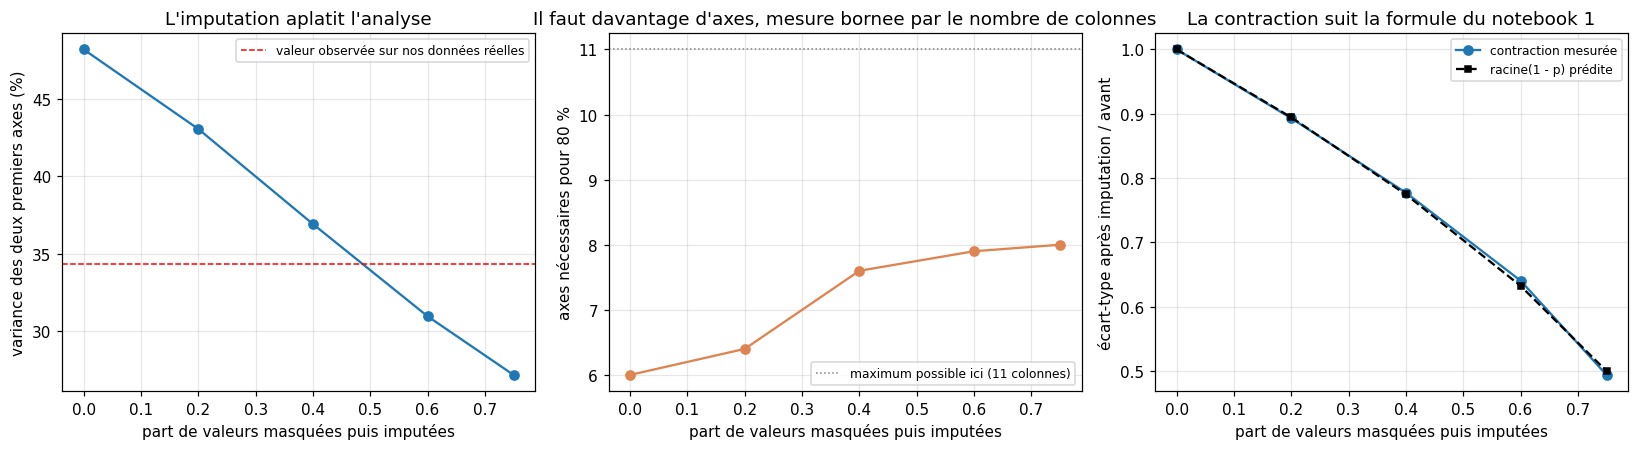

In [10]:
figure, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].plot(masquage.index, 100 * masquage["PC1 + PC2"], marker="o")
axes[0].axhline(100 * variance[:2].sum(), color="red", linestyle="--",
                linewidth=1, label="valeur observée sur nos données réelles")
axes[0].set(xlabel="part de valeurs masquées puis imputées",
            ylabel="variance des deux premiers axes (%)",
            title="L'imputation aplatit l'analyse")
axes[0].legend(fontsize=8)

axes[1].plot(masquage.index, masquage["axes pour 80 %"], marker="o",
             color="#DD8452")
# Pas de ligne de comparaison ici : le nombre d'axes est borne par le nombre
# de colonnes, et la base de controle en compte deux fois moins que nos
# donnees reelles. Les deux ne sont donc pas comparables (cf. commentaire).
axes[1].axhline(base.shape[1], color="grey", linestyle=":", linewidth=1,
                label=f"maximum possible ici ({base.shape[1]} colonnes)")
axes[1].set(xlabel="part de valeurs masquées puis imputées",
            ylabel="axes nécessaires pour 80 %",
            title="Il faut davantage d'axes, mesure bornee par "
                  "le nombre de colonnes")
axes[1].legend(fontsize=8)

axes[2].plot(masquage.index, masquage["contraction mesurée"], marker="o",
             label="contraction mesurée")
axes[2].plot(masquage.index, masquage["racine(1 - p) attendue"], "k--",
             marker="s", markersize=4, label="racine(1 - p) prédite")
axes[2].set(xlabel="part de valeurs masquées puis imputées",
            ylabel="écart-type après imputation / avant",
            title="La contraction suit la formule du notebook 1")
axes[2].legend(fontsize=8)

figure.tight_layout()
figure.savefig(OUT / "imputation_et_acp.png", dpi=150)
plt.show()

### 4.4 Le résultat, et la chaîne d'explication complète

**L'imputation aplatit bien l'analyse, et fortement.** À données rigoureusement
constantes, masquer puis imputer fait chuter la variance des deux premiers axes
de façon monotone, et augmente le nombre d'axes nécessaires.

**La contraction des écarts-types suit précisément la formule du notebook 1.** Le
troisième graphique superpose la contraction mesurée et la prédiction en
`racine(1 - p)` : les deux courbes se confondent. La chaîne d'explication est
donc complète et vérifiée de bout en bout :

```
imputation par une constante
   -> contraction des écarts-types en racine(p)       [vérifié, notebook 1]
   -> contraction des corrélations                    [même mécanisme]
   -> axes principaux expliquant moins de variance    [vérifié ici]
```

**Un seul des deux indicateurs est comparable à nos données réelles, et il faut
le dire pour ne pas surinterpréter la figure.**

La variance des deux premiers axes **est** comparable : c'est une proportion,
donc elle ne dépend pas directement du nombre de colonnes. La ligne rouge du
premier graphique marque la valeur observée sur nos vraies données, et elle est
atteinte pour un niveau de masquage de l'ordre de celui que subissent
effectivement nos colonnes les moins renseignées. **La concordance est donc
bonne, et c'est l'argument central de cette section.**

Le nombre d'axes nécessaires, en revanche, **n'est pas comparable**. Il est borné
par le nombre de colonnes, et notre base de contrôle en compte deux fois moins
que nos données réelles. La simulation ne pourrait donc pas atteindre le nombre
d'axes observé même avec un masquage total, et le second graphique indique cette
borne en pointillés gris. Il montre une tendance, à savoir que l'imputation
augmente le nombre d'axes nécessaires, mais son niveau absolu ne se compare pas
au nôtre.

C'est précisément le biais qui entachait notre première tentative, et nous
l'évitons cette fois en ne comparant que ce qui est comparable.

### Conséquence, et il faut être précis sur sa portée

**La structure de nos entrées est moins plate que notre analyse ne le suggère.**
Une partie de la platitude observée est produite par l'imputation, pas par les
données.

**Mais la conclusion qualitative du notebook tient.** Même sans aucune
imputation, sur la base de contrôle entièrement renseignée, il faut six axes pour
atteindre 80 % de la variance, et les deux premiers n'en expliquent qu'environ la
moitié. **La structure reste multidimensionnelle**, et une représentation en deux
dimensions reste insuffisante.

**Ce qu'il ne faut pas en conclure**, et le notebook 4 le démontrera :
l'imputation ne coûte **rien en performance prédictive**. Déformer la structure
et dégrader la prédiction sont deux choses différentes. Un arbre de décision
place une coupure à côté de la constante d'imputation, ce qui revient à séparer
les lignes renseignées des autres : il récupère par un détour l'information
d'absence.

**La critique de l'imputation doit donc viser l'analyse exploratoire, et non la
prédiction.**

### 4.5 Ce que les axes représentent

L'analyse ne dit pas quelles variables font une bonne soudure, mais elle dit
lesquelles varient ensemble. Nous regardons les corrélations entre chaque
variable d'origine et les deux premiers axes.

Deux grandeurs sont souvent confondues et méritent d'être distinguées. La
**corrélation** d'une variable avec un axe dit si elles varient ensemble, entre
-1 et 1. La **contribution** dit quelle part de l'axe est portée par cette
variable, et elle se somme à 100 % sur l'ensemble des variables.

In [11]:
composantes = pd.DataFrame(
    acp.components_[:2].T, index=numeriques_prepares,
    columns=["axe 1", "axe 2"])
for axe_nom, numero in [("axe 1", 0), ("axe 2", 1)]:
    composantes[f"corrélation {axe_nom}"] = (
        acp.components_[numero] * np.sqrt(acp.explained_variance_[numero]))
    composantes[f"contribution {axe_nom} (%)"] = (
        100 * acp.components_[numero] ** 2)

print("Variables les plus liées au premier axe :")
display(composantes.reindex(
    composantes["contribution axe 1 (%)"].sort_values(ascending=False).index)
    [["corrélation axe 1", "contribution axe 1 (%)"]].head(6).round(3))
print("Variables les plus liées au deuxième axe :")
display(composantes.reindex(
    composantes["contribution axe 2 (%)"].sort_values(ascending=False).index)
    [["corrélation axe 2", "contribution axe 2 (%)"]].head(6).round(3))

Variables les plus liées au premier axe :


,corrélation axe 1,contribution axe 1 (%)
Cr,0.731,13.366
PWHT_T_C,0.662,10.955
N_ppm,0.648,10.488
Current_A,-0.617,9.516
Mo,0.601,9.044
HeatInput_kJmm,-0.596,8.867


Variables les plus liées au deuxième axe :


,corrélation axe 2,contribution axe 2 (%)
Voltage_V,0.675,12.775
Current_A,0.630,11.139
HeatInput_kJmm,0.612,10.512
Mo,0.565,8.959
C,0.557,8.716
S,0.548,8.416


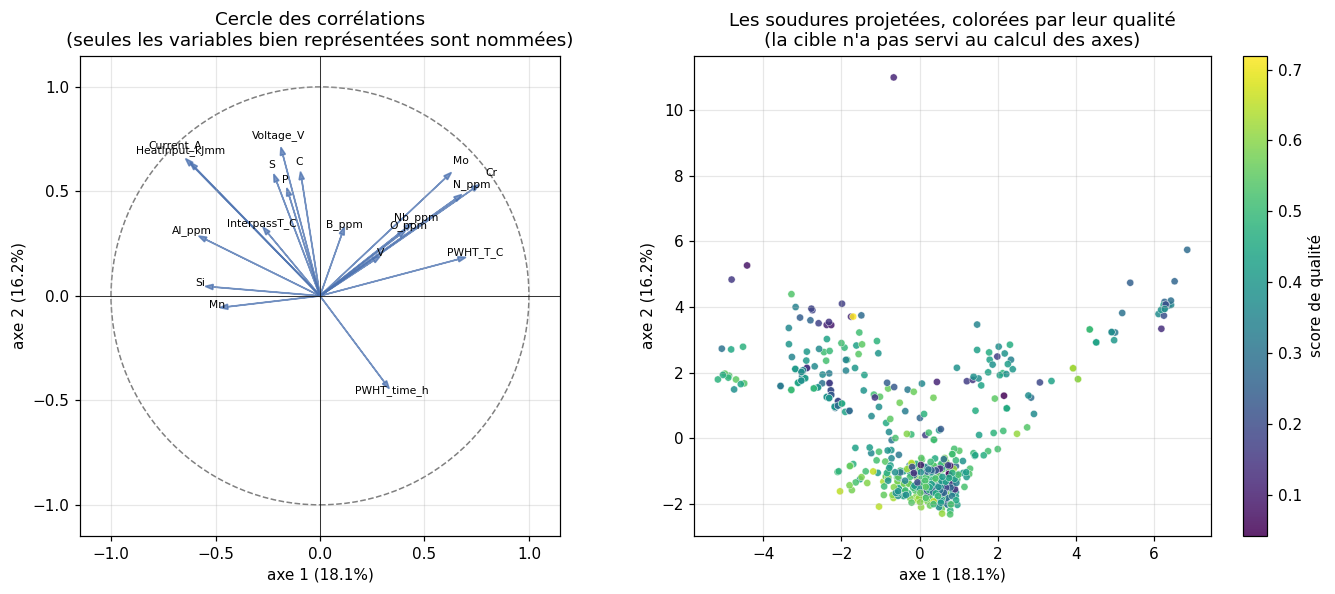

In [12]:
coordonnees = pd.DataFrame(acp.transform(Z)[:, :2], index=X.index,
                           columns=["axe 1", "axe 2"])

figure, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# Cercle des corrélations.
cercle = plt.Circle((0, 0), 1, fill=False, color="grey", linestyle="--")
axes[0].add_patch(cercle)
for variable in numeriques_prepares:
    x_fleche = composantes.loc[variable, "corrélation axe 1"]
    y_fleche = composantes.loc[variable, "corrélation axe 2"]
    if np.hypot(x_fleche, y_fleche) > 0.3:
        axes[0].arrow(0, 0, x_fleche, y_fleche, head_width=0.025,
                      color="#4C72B0", alpha=0.75)
        axes[0].text(x_fleche * 1.12, y_fleche * 1.12, variable, fontsize=7,
                     ha="center")
axes[0].axhline(0, color="black", linewidth=0.5)
axes[0].axvline(0, color="black", linewidth=0.5)
axes[0].set(xlim=(-1.15, 1.15), ylim=(-1.15, 1.15),
            xlabel=f"axe 1 ({variance[0]:.1%})",
            ylabel=f"axe 2 ({variance[1]:.1%})",
            title="Cercle des corrélations\n(seules les variables bien "
                  "représentées sont nommées)")
axes[0].set_aspect("equal")

# Projection des soudures, colorées par la cible. La cible n'a PAS participé
# au calcul des axes : c'est une lecture a posteriori.
nuage = axes[1].scatter(coordonnees["axe 1"], coordonnees["axe 2"], c=y, s=22,
                        cmap="viridis", alpha=0.85, edgecolor="white",
                        linewidth=0.3)
figure.colorbar(nuage, ax=axes[1], label="score de qualité")
axes[1].set(xlabel=f"axe 1 ({variance[0]:.1%})",
            ylabel=f"axe 2 ({variance[1]:.1%})",
            title="Les soudures projetées, colorées par leur qualité\n"
                  "(la cible n'a pas servi au calcul des axes)")

figure.tight_layout()
figure.savefig(OUT / "acp_projection.png", dpi=150)
plt.show()

### Ce que la projection montre, et ce qu'elle ne montre pas

**Le nuage coloré par la qualité ne fait apparaître aucune séparation nette.** Il
n'y a pas une région des bonnes soudures et une région des mauvaises : les
couleurs sont mêlées.

**Il ne faut pas en conclure que la qualité est imprévisible.** Deux raisons
l'interdisent.

D'abord ces deux axes ne portent qu'un tiers de la variance : l'information qui
sépare les soudures peut très bien vivre dans les axes suivants, qui ne sont pas
représentés.

Ensuite les axes ont été construits **sans regarder la cible**. Rien ne les
oblige à s'aligner sur ce qui distingue les bonnes soudures. Une direction peut
être la plus variable du nuage sans avoir le moindre rapport avec la qualité.

**La lecture correcte est donc : la qualité ne se lit pas sur les deux premières
directions de plus grande variance des entrées.** C'est une information utile,
car elle annonce qu'il faudra des modèles capables d'exploiter plusieurs
dimensions à la fois, et non une règle simple sur deux variables. La section
suivante confirme ce diagnostic par une autre méthode.

## 5. Les soudures se regroupent-elles par qualité ?

Dernière exploration non supervisée, et elle répond à une question précise et
légitime.

Si les soudures formaient des **groupes naturels** dans l'espace des
compositions, et si ces groupes correspondaient à des niveaux de qualité, alors
prédire la qualité se réduirait à reconnaître le groupe. Ce serait une solution
simple et très interprétable.

Nous utilisons l'algorithme des **k-moyennes**, qui cherche `k` groupes en
minimisant la distance de chaque soudure au centre de son groupe. Comme il
raisonne en distances, la standardisation est indispensable.

### 5.1 Combien de groupes ?

Deux critères, et nous exigeons qu'ils s'accordent.

La **silhouette** compare, pour chaque soudure, sa distance moyenne aux membres
de son propre groupe à sa distance moyenne au groupe voisin le plus proche. Elle
vaut 1 si les groupes sont parfaitement séparés, 0 si une soudure est à égale
distance de deux groupes, et elle est négative si la soudure est plus proche d'un
autre groupe que du sien.

La **stabilité** vérifie que les groupes ne sont pas un accident de
l'échantillon. Nous rééchantillonnons les soudures, refaisons le partitionnement,
et mesurons l'accord avec le partitionnement de référence par l'indice de Rand
ajusté, qui vaut 1 pour un accord parfait et 0 pour un accord dû au hasard.

In [13]:
Z_groupes = X_prepare.to_numpy()
generateur_kmeans = np.random.default_rng(GRAINE)
soudures = groupes.unique()

lignes_k = []
for k in range(2, 9):
    modele = KMeans(n_clusters=k, n_init=20, random_state=GRAINE).fit(Z_groupes)
    reference = modele.labels_
    accords = []
    for _ in range(10):
        tirage = set(generateur_kmeans.choice(soudures, size=len(soudures),
                                              replace=True))
        masque = groupes.isin(tirage).to_numpy()
        if masque.sum() < 100:
            continue
        rejoue = KMeans(n_clusters=k, n_init=10,
                        random_state=GRAINE).fit(Z_groupes[masque])
        accords.append(adjusted_rand_score(reference[masque], rejoue.labels_))
    lignes_k.append({
        "k": k,
        "silhouette": silhouette_score(Z_groupes, reference),
        "stabilité (Rand ajusté)": np.mean(accords),
        "inertie": modele.inertia_,
    })

choix_k = pd.DataFrame(lignes_k).set_index("k")
stables = choix_k[choix_k["stabilité (Rand ajusté)"] >= 0.75]
K_RETENU = int(stables["silhouette"].idxmax()) if len(stables) else \
    int(choix_k["silhouette"].idxmax())

print(f"Règle retenue : meilleure silhouette parmi les k dont la stabilité")
print(f"atteint 0,75. Résultat : k = {K_RETENU}.")
display(choix_k.round(3))

Règle retenue : meilleure silhouette parmi les k dont la stabilité
atteint 0,75. Résultat : k = 4.


,silhouette,stabilité (Rand ajusté),inertie
k,,,
2,0.266,0.349,10211.399
3,0.294,0.932,8686.569
4,0.314,0.911,8023.655
5,0.168,0.487,7561.345
6,0.172,0.742,6944.518
7,0.301,0.487,6595.095
8,0.200,0.739,6108.329


In [14]:
kmeans = KMeans(n_clusters=K_RETENU, n_init=20,
                random_state=GRAINE).fit(Z_groupes)
appartenance = pd.Series(kmeans.labels_, index=X.index, name="groupe_kmeans")

table = pd.DataFrame({"groupe_kmeans": appartenance, "qualité": y,
                      "soudure": groupes})
resume = table.groupby("groupe_kmeans").agg(
    lignes=("qualité", "size"),
    soudures=("soudure", "nunique"),
    qualité_moyenne=("qualité", "mean"),
    qualité_écart_type=("qualité", "std"),
    qualité_minimum=("qualité", "min"),
    qualité_maximum=("qualité", "max"))
display(resume.round(3))

# Le groupe suffit-il à prédire la qualité ? On prédit la moyenne de son
# groupe, et on compare à une référence constante et à ce qu'obtient un
# modèle supervisé dans le notebook 4.
poids_tableau = poids.to_numpy()
moyennes = table.groupby("groupe_kmeans")["qualité"].mean()
prediction_groupe = appartenance.map(moyennes)
constante = np.average(y, weights=poids_tableau)

erreur_groupe = np.sqrt(mean_squared_error(y, prediction_groupe,
                                           sample_weight=poids_tableau))
erreur_constante = np.sqrt(mean_squared_error(
    y, np.full(len(y), constante), sample_weight=poids_tableau))

print(f"Erreur en prédisant la moyenne du groupe k-moyennes : "
      f"{erreur_groupe:.4f}")
print(f"Erreur d'une référence constante                    : "
      f"{erreur_constante:.4f}")
print(f"\nGain du groupe sur la référence : "
      f"{1 - erreur_groupe / erreur_constante:.1%}")
print("Pour mémoire, le notebook 4 obtient environ 39 % avec un modèle")
print("supervisé sur les mêmes entrées.")

,lignes,soudures,qualité_moyenne,qualité_écart_type,qualité_minimum,qualité_maximum
groupe_kmeans,,,,,,
0,357,250,0.438,0.134,0.042,0.659
1,108,77,0.363,0.129,0.079,0.720
2,33,28,0.358,0.129,0.049,0.547
3,29,24,0.378,0.133,0.130,0.704


Erreur en prédisant la moyenne du groupe k-moyennes : 0.1281
Erreur d'une référence constante                    : 0.1337

Gain du groupe sur la référence : 4.1%
Pour mémoire, le notebook 4 obtient environ 39 % avec un modèle
supervisé sur les mêmes entrées.


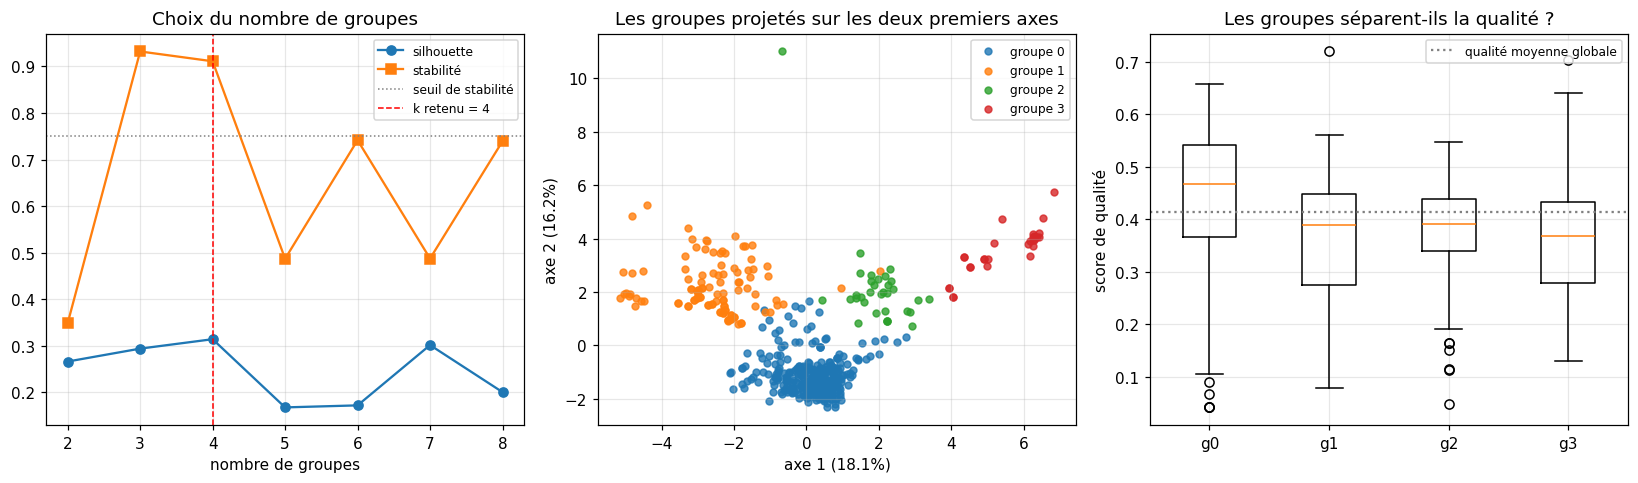

In [15]:
figure, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].plot(choix_k.index, choix_k["silhouette"], marker="o",
             label="silhouette")
axes[0].plot(choix_k.index, choix_k["stabilité (Rand ajusté)"], marker="s",
             label="stabilité")
axes[0].axhline(0.75, color="grey", linestyle=":", linewidth=1,
                label="seuil de stabilité")
axes[0].axvline(K_RETENU, color="red", linestyle="--", linewidth=1,
                label=f"k retenu = {K_RETENU}")
axes[0].set(xlabel="nombre de groupes", title="Choix du nombre de groupes")
axes[0].legend(fontsize=8)

for groupe in sorted(appartenance.unique()):
    masque = appartenance == groupe
    axes[1].scatter(coordonnees.loc[masque, "axe 1"],
                    coordonnees.loc[masque, "axe 2"], s=20, alpha=0.8,
                    label=f"groupe {groupe}")
axes[1].set(xlabel=f"axe 1 ({variance[0]:.1%})",
            ylabel=f"axe 2 ({variance[1]:.1%})",
            title="Les groupes projetés sur les deux premiers axes")
axes[1].legend(fontsize=8)

donnees_boites = [table.loc[table["groupe_kmeans"] == g, "qualité"].to_numpy()
                  for g in sorted(appartenance.unique())]
axes[2].boxplot(donnees_boites,
                tick_labels=[f"g{g}" for g in sorted(appartenance.unique())])
axes[2].axhline(y.mean(), color="grey", linestyle=":",
                label="qualité moyenne globale")
axes[2].set(ylabel="score de qualité",
            title="Les groupes séparent-ils la qualité ?")
axes[2].legend(fontsize=8)

figure.tight_layout()
figure.savefig(OUT / "kmeans.png", dpi=150)
plt.show()

### 5.2 La réponse est non, et c'est un résultat

**Les boîtes se recouvrent largement.** Chaque groupe contient des soudures de
toutes qualités, et les moyennes par groupe sont proches les unes des autres.

**Prédire la moyenne de son groupe ne gagne qu'une faible fraction de l'erreur
d'une référence qui ne sait rien**, très loin de ce qu'obtient un modèle
supervisé sur les mêmes entrées.

**Un résultat négatif bien établi est un résultat**, et celui-ci dit quelque
chose de précis sur le problème : **les regroupements naturels des soudures ne
sont pas des regroupements de qualité.**

Les groupes trouvés correspondent à des familles de nuances d'acier et de
procédés, ce que le graphique de projection suggère et que les centres des
groupes confirment. C'est cohérent : les k-moyennes séparent selon les
directions de plus grande variance, et la section 4.5 a montré que la qualité ne
s'y lit pas.

**Deux soudures de composition voisine peuvent avoir des qualités très
différentes**, parce que ce sont des détails du procédé et du traitement
thermique qui font la différence. Le notebook 4 le confirmera : le traitement
thermique post-soudage est l'une des variables les plus importantes pour prédire
la qualité.

**Conséquence pour la suite : il faut une approche supervisée.** Un découpage non
supervisé de l'espace des compositions ne suffit pas, et nous l'avons vérifié
plutôt que de le supposer.

## 6. Ce que ce notebook établit

### 6.1 La préparation retenue

Cinq décisions, chacune justifiée et dont le coût est connu.

Les colonnes renseignées à moins de 25 % sont écartées, et **aucune colonne ne se
trouve près de ce seuil**, donc sa valeur exacte n'a pas d'importance. Les valeurs
numériques absentes sont remplacées par la médiane, plus robuste que la moyenne.
Les valeurs catégorielles absentes reçoivent une catégorie dédiée, car l'absence
porte de l'information. Les catégories sont encodées en indicateurs avec une
modalité de référence retirée, pour éviter la dépendance linéaire. La
standardisation est activée pour les seuls modèles qui en ont besoin.

**Toute la préparation est réajustée dans chaque pli de validation.** Quatre
choses fuiraient autrement : médianes, paramètres de standardisation, modalités
vues et sélection des colonnes. C'est la raison d'être du pipeline, et nous avons
mesuré que les médianes varient effectivement d'un pli à l'autre.

### 6.2 Les limites de la préparation, mesurées

**Les médianes d'imputation ne sont pas pondérées par soudure**, alors que tout
le reste du projet l'est. Nous avons mesuré l'écart : nul pour la majorité des
colonnes, important pour quelques colonnes peu renseignées. Nous conservons ce
choix en le documentant, et nous indiquons comment le corriger.

**Les indicateurs de valeurs manquantes** sont utiles aux modèles à pénalité et
nuisibles aux autres, ce que le notebook d'exploration 09 a mesuré. C'est un
compromis biais-variance, et il n'y a pas de réponse unique.

### 6.3 L'exploration non supervisée

**La structure des entrées est multidimensionnelle.** Deux axes ne suffisent pas,
et il en faut une dizaine pour résumer 80 % de la variance.

**Une partie de cette platitude est produite par notre imputation**, et nous
l'avons démontré par un protocole qui tient tout constant sauf l'imputation,
après avoir constaté que notre première comparaison était biaisée. La chaîne est
vérifiée de bout en bout : imputation, contraction des écarts-types en
`racine(p)`, aplatissement des axes.

**Mais la conclusion qualitative tient** : même sans aucune imputation, il faut
six axes pour atteindre 80 %.

**La qualité ne se lit pas sur les deux premières directions de plus grande
variance**, et les groupes naturels des soudures ne sont pas des groupes de
qualité. Les deux méthodes non supervisées concordent, et elles justifient
l'approche supervisée du notebook 4.

### 6.4 Ce qui reste ouvert

L'imputation par régression, présentée dans le TD 1, n'a pas été comparée à
l'imputation par la médiane. Nous avons en revanche comparé cette dernière à un
modèle traitant nativement les valeurs absentes, dans le notebook d'exploration
10, et l'imputation par la médiane n'est pas pénalisante en prédiction.

L'analyse en composantes principales n'est pas pondérée par soudure, alors
qu'elle devrait l'être pour la même raison que tout le reste. Les lignes d'une
même soudure y participent toutes, donc une soudure testée vingt fois pèse vingt
fois dans le calcul des axes.

In [16]:
resume_acp.to_csv(OUT / "variance_expliquee.csv", index_label="axe")
composantes.to_csv(OUT / "axes_variables.csv", index_label="variable")
coordonnees.to_csv(OUT / "coordonnees_acp.csv", index_label="row_id")
masquage.to_csv(OUT / "imputation_et_acp.csv", index_label="part_masquee")
effet_ponderation.to_csv(OUT / "medianes_ponderees.csv", index_label="colonne")
choix_k.to_csv(OUT / "kmeans_choix_k.csv", index_label="k")
resume.to_csv(OUT / "kmeans_groupes.csv", index_label="groupe_kmeans")
pd.DataFrame(verification).to_csv(OUT / "verification_plis.csv", index=False)

choix = {
    "seuil_remplissage": SEUIL_REMPLISSAGE,
    "colonnes_gardees": gardees,
    "colonnes_ecartees": ecartees,
    "imputation_numerique": "mediane, non ponderee",
    "imputation_categorielle": "categorie manquant",
    "encodage": "one-hot, une modalite de reference retiree",
    "standardisation": "activee pour les modeles sensibles aux echelles",
    "reajustement": "dans chaque pli de validation",
    "acp_variance_deux_axes": float(variance[:2].sum()),
    "acp_axes_pour_80": int(np.argmax(cumul >= 0.80) + 1),
    "kmeans_k_retenu": K_RETENU,
    "kmeans_gain_sur_reference": float(1 - erreur_groupe / erreur_constante),
}
(OUT / "choix_preparation.json").write_text(
    json.dumps(choix, ensure_ascii=False, indent=2), encoding="utf-8")

print("Résultats enregistrés :")
for chemin in sorted(OUT.iterdir()):
    print("   ", chemin.name)
print("\nLe notebook 4 entraîne les modèles sur ces entrées préparées.")

Résultats enregistrés :
    acp_projection.png
    axes_variables.csv
    choix_preparation.json
    coordonnees_acp.csv
    imputation_et_acp.csv
    imputation_et_acp.png
    kmeans.png
    kmeans_choix_k.csv
    kmeans_groupes.csv
    medianes_ponderees.csv
    variance_expliquee.csv
    verification_plis.csv

Le notebook 4 entraîne les modèles sur ces entrées préparées.
